In [1]:
import os
from pathlib import Path
from typing import Literal, Optional, List

import numpy as np
import math
import uproot as uproot
import pickle
import pandas as pd
import awkward as ak
from dataclasses import dataclass, field

import matplotlib.pyplot as plt
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white"})
import matplotlib.colors
from matplotlib.colors import LinearSegmentedColormap
from matplotlib import ticker
from matplotlib.ticker import (AutoMinorLocator, MultipleLocator)
from matplotlib import gridspec
import seaborn as sns

os.environ["PROJECT_PATH"] = "/home/syebes/lambda-ana"
project_path = Path(os.environ["PROJECT_PATH"])
sys.path.append(str(project_path))

# My imports
from src.driver import AnalysisDriver
import src.branches as branches
from src.cuts import CutConfig, create_cut

# Load files

In [2]:
# POT taken from preselection stage

lambda_pot = 1.428596135616784e+23
aurora_pot = 5.401777280854836e+20

In [3]:
lambda_file = "/exp/sbnd/data/users/syebes/eafData/fransOutputs/lambdaFransOutput.root"
aurora_file = "/exp/sbnd/data/users/syebes/eafData/fransOutputs/devFransOutput.root"

frans_tdir = "FRANSProducer/fransTree"

In [4]:
lambda_tree = uproot.open(lambda_file)[frans_tdir]
aurora_tree = uproot.open(aurora_file)[frans_tdir]

In [5]:
max_entry = None
indices =['run_id', 'subrun_id', 'event_id', 'slice_id']

lambda_df = pd.DataFrame(lambda_tree.arrays(branches.frans, library="np", entry_stop=max_entry))
aurora_df = pd.DataFrame(aurora_tree.arrays(branches.frans, library="np", entry_stop=max_entry))

lambda_df.set_index(indices, inplace=True)
aurora_df.set_index(indices, inplace=True)

In [6]:
pot_3y = 7e20

lambda_scale = pot_3y / lambda_pot
aurora_scale = pot_3y / aurora_pot

aurora_sgnl_mask = (aurora_df.n_lambda > 0) | (aurora_df.n_sigma0 > 0)

lambda_df['scale'] = pot_3y / (lambda_pot + aurora_pot)
aurora_df['scale'] = aurora_scale
aurora_df.loc[aurora_sgnl_mask, 'scale'] = pot_3y / (lambda_pot + aurora_pot)

In [7]:
# Cosmic scaling

'''
hyp_rate = len(aurora_sgnl_mask.groupby(['event_id', 'run_id', 'subrun_id']).any()) / len(aurora_df.groupby(['event_id', 'run_id', 'subrun_id']))

events_i_have = len(aurora_df.groupby(['event_id', 'run_id', 'subrun_id'])) + len(lambda_df.groupby(['event_id', 'run_id', 'subrun_id']))
total_events = len(aurora_df.groupby(['event_id', 'run_id', 'subrun_id'])) + len(lambda_df.groupby(['event_id', 'run_id', 'subrun_id'])) / hyp_rate + len(lambda_df.groupby(['event_id', 'run_id', 'subrun_id'])) * (1-hyp_rate)/hyp_rate

aurora_cosmic_mask = (aurora_df.gen_index > 1)
lambda_cosmic_mask = (lambda_df.gen_index > 1)

#aurora_df.loc[aurora_cosmic_mask, 'scale'] = pot_3y / aurora_pot * hyp_cosmic_scaling
#lambda_df.loc[lambda_cosmic_mask, 'scale'] = pot_3y / (lambda_pot + aurora_pot) * hyp_cosmic_scaling

cosmic_scaling = pot_3y / (lambda_pot + aurora_pot) * total_events / events_i_have

aurora_df.loc[aurora_cosmic_mask, 'scale'] = pot_3y / (lambda_pot + aurora_pot) * cosmic_scaling
lambda_df.loc[lambda_cosmic_mask, 'scale'] = pot_3y / (lambda_pot + aurora_pot) * cosmic_scaling
'''

"\nhyp_rate = len(aurora_sgnl_mask.groupby(['event_id', 'run_id', 'subrun_id']).any()) / len(aurora_df.groupby(['event_id', 'run_id', 'subrun_id']))\n\nevents_i_have = len(aurora_df.groupby(['event_id', 'run_id', 'subrun_id'])) + len(lambda_df.groupby(['event_id', 'run_id', 'subrun_id']))\ntotal_events = len(aurora_df.groupby(['event_id', 'run_id', 'subrun_id'])) + len(lambda_df.groupby(['event_id', 'run_id', 'subrun_id'])) / hyp_rate + len(lambda_df.groupby(['event_id', 'run_id', 'subrun_id'])) * (1-hyp_rate)/hyp_rate\n\naurora_cosmic_mask = (aurora_df.gen_index > 1)\nlambda_cosmic_mask = (lambda_df.gen_index > 1)\n\n#aurora_df.loc[aurora_cosmic_mask, 'scale'] = pot_3y / aurora_pot * hyp_cosmic_scaling\n#lambda_df.loc[lambda_cosmic_mask, 'scale'] = pot_3y / (lambda_pot + aurora_pot) * hyp_cosmic_scaling\n\ncosmic_scaling = pot_3y / (lambda_pot + aurora_pot) * total_events / events_i_have\n\naurora_df.loc[aurora_cosmic_mask, 'scale'] = pot_3y / (lambda_pot + aurora_pot) * cosmic_scalin

In [8]:
df = pd.concat([lambda_df, aurora_df])

# Michel tagging column

In [9]:
'''
df["michel_final_score"] = np.where(
    df["michel_score"] == -1,
    2,
    df["michel_score"]
)'''

df["michel_final_score"] = np.where(
    ~df["michel_vars_computed"],
    2,
    df["michel_score"]
)

# Preselection

In [10]:
preselected_mask = df.pre_pass

pre_df = df[preselected_mask]

# Selection

import importlib
import src

importlib.reload(src.driver)
importlib.reload(src.plotter)
importlib.reload(src.frans_branches)
importlib.reload(src.cuts)
from src.driver import AnalysisDriver
from src.frans_branches import branches
from src.cuts import CutConfig, create_cut

In [11]:
import yaml

with open("../../config/cuts_config.yaml", "r") as f:
    config = yaml.safe_load(f)

In [12]:
cuts_config = []

for cut_cfg in config['frans_cuts'].values():
    cfg = CutConfig(
        cut = create_cut(cut_cfg['cut']),
        **{k: v for k, v in cut_cfg.items() if k != "cut"}
    )

    cuts_config.append(cfg)

In [13]:
driver = AnalysisDriver(pre_df, cuts_config)

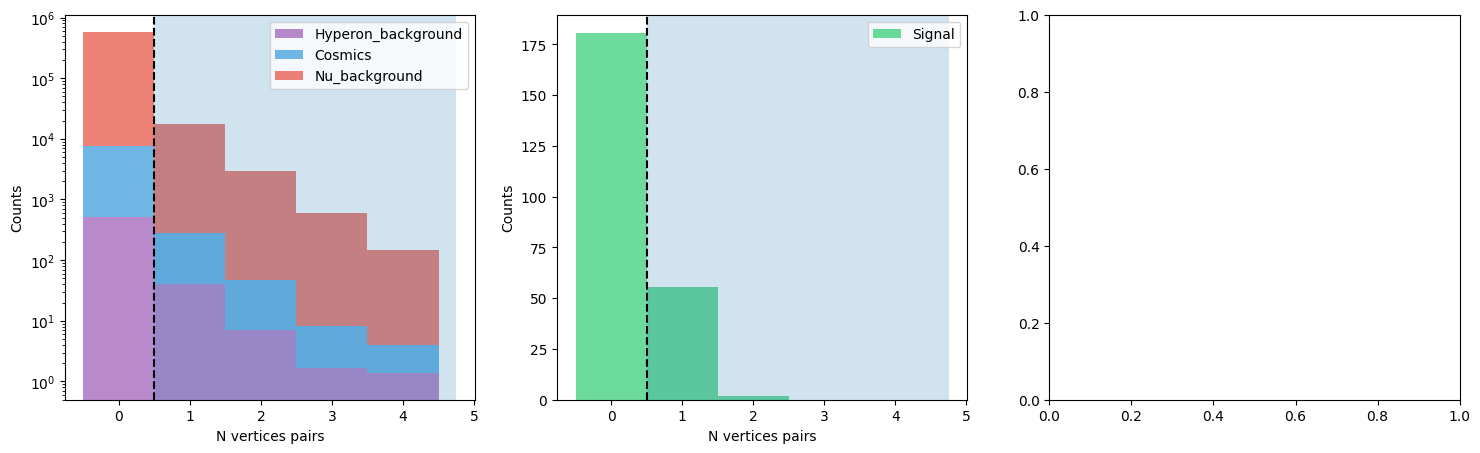

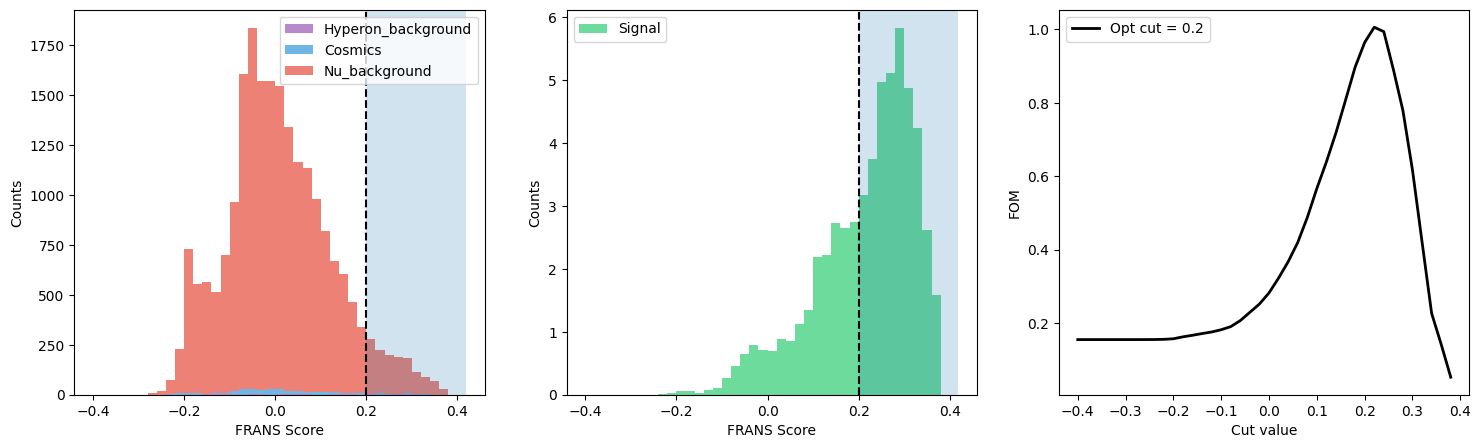

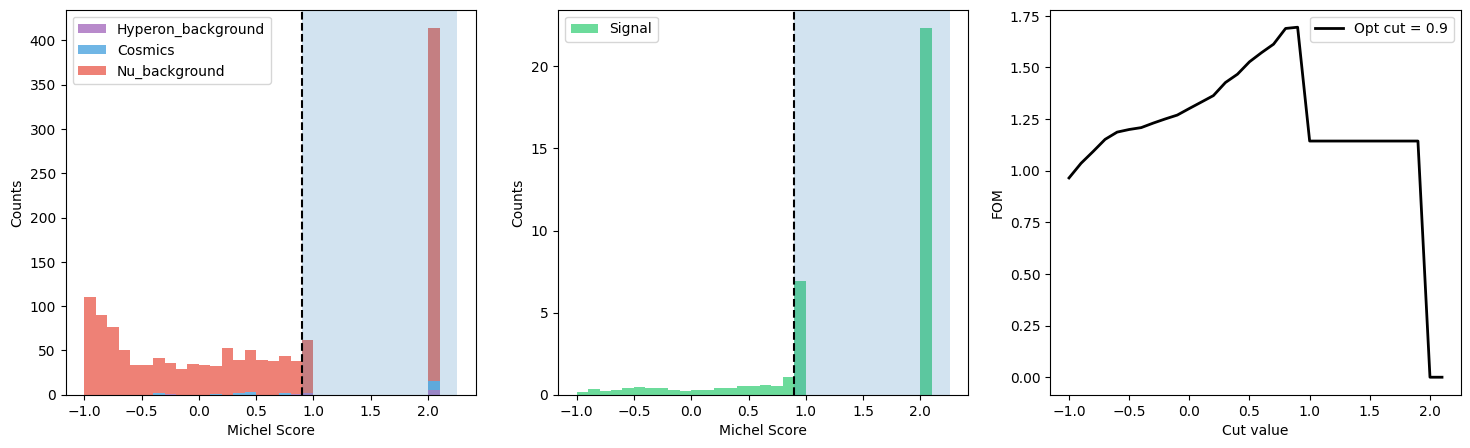

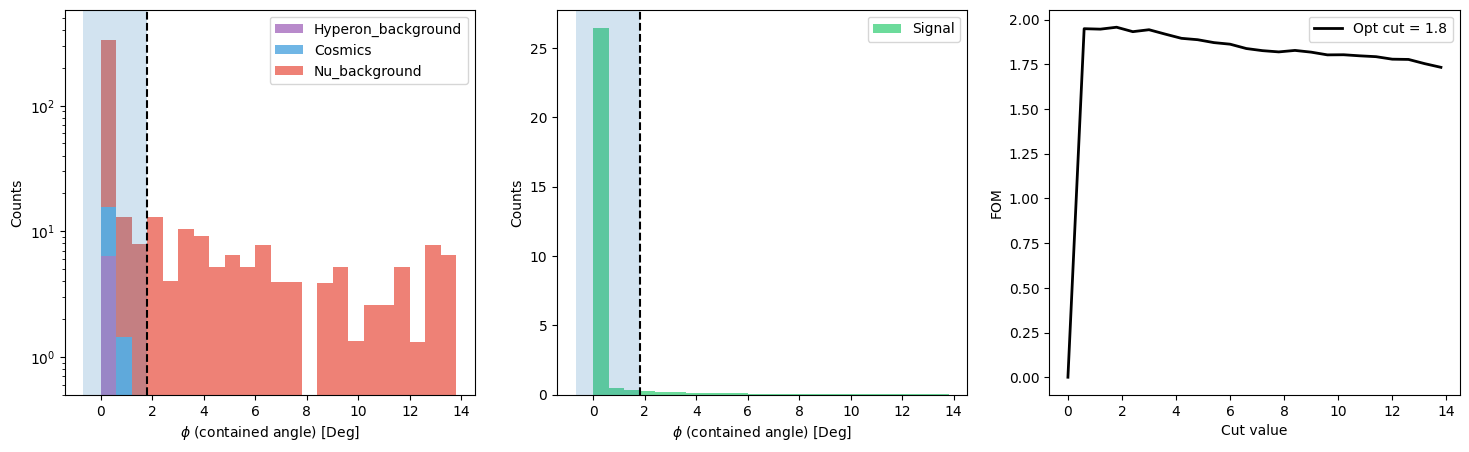

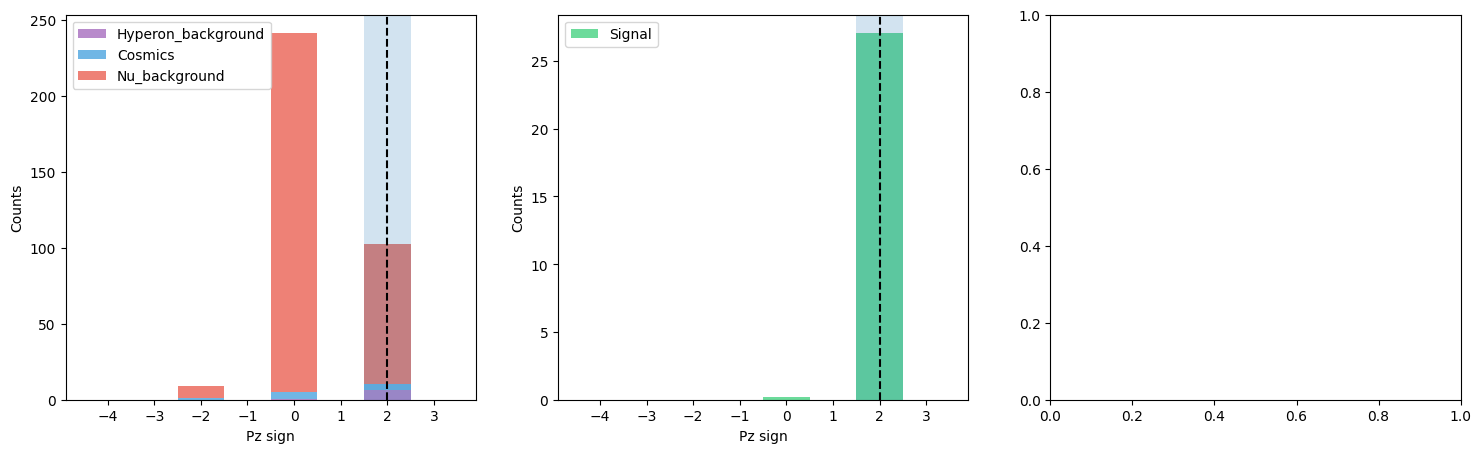

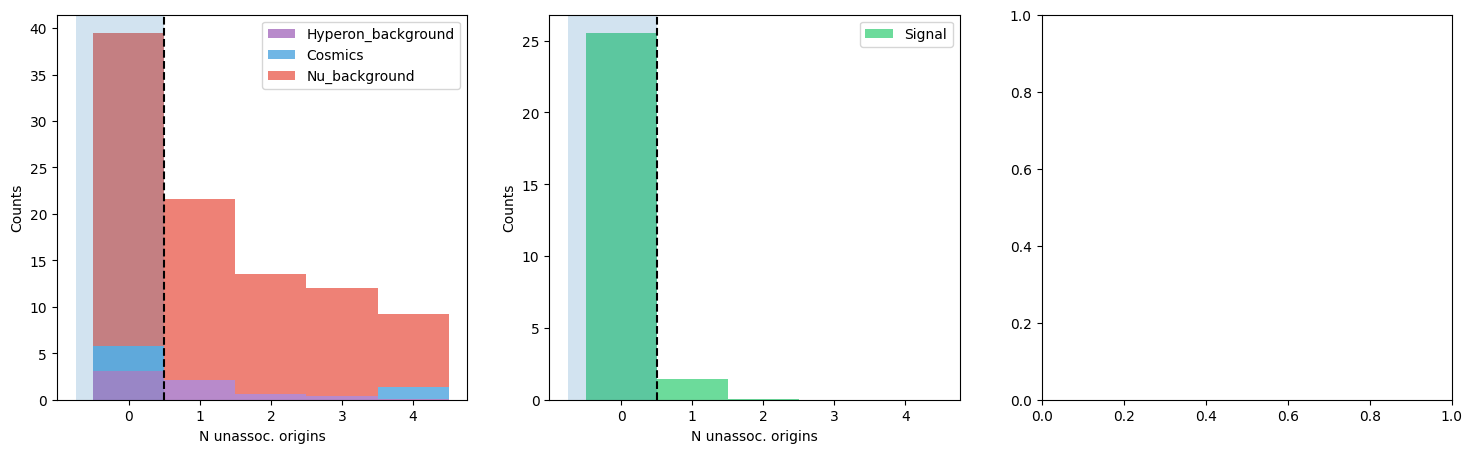

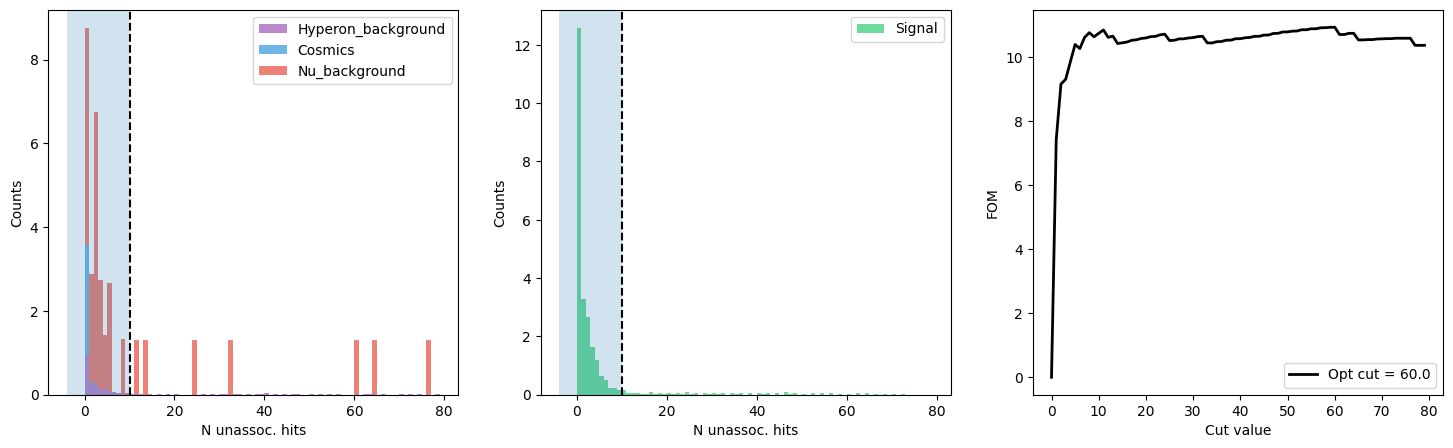

,Stage,Cut value,Signal,Hyperon_background,Cosmics,Nu_background,Cut efficiency (%),Total efficiency (%),Purity (%),Cut bck rejection (%),Total bck rejection (%)
0,N vertices pairs,>= 1,57.6,49.9,293.2,2.1e+04,24.20,13.82,0.27,96.46,99.9185
1,FRANS Score,> 0.2,37.0,10.9,18.3,1.4e+03,64.13,8.87,2.61,93.54,99.9947
2,Michel Score,>= 0.9,29.2,7.4,10.5,457.4,79.10,7.01,5.80,65.55,99.9982
3,$\phi$ (contained angle) [Deg],< 1.8,27.3,6.6,10.5,335.6,93.27,6.54,7.18,25.79,99.9987
4,Pz sign,== 2,27.1,6.4,4.0,92.0,99.23,6.49,20.90,70.96,99.9996
5,N unassoc. origins,< 1,25.5,3.1,2.7,33.7,94.34,6.12,39.28,61.46,99.9998
6,N unassoc. hits,< 10,23.1,2.0,2.7,22.0,90.52,5.54,46.43,32.45,99.9999


In [14]:
driver.plot_cuts()
driver.get_cuts_performance(**config['initial_amounts'])

In [15]:
final_df = driver.get_final_df()

In [16]:
len(final_df.groupby(level=['run_id', 'subrun_id', 'event_id']))

5171

In [17]:
len(final_df)

4997

In [21]:
len(final_df[~final_df.is_lambda_signal & (final_df.scale>1)])

19

In [18]:
len(final_df[~final_df.is_lambda_signal])

437

In [17]:
len(final_df[final_df.is_lambda_signal])

4734

# Load FRANS PID tree

In [22]:
pid_tdir = "lambdaPidPandoraAna/CalorimetryTree"

lambda_pid_tree = uproot.open(lambda_file)[pid_tdir]
aurora_pid_tree = uproot.open(aurora_file)[pid_tdir]

In [23]:
lambda_pid_df = pd.DataFrame(lambda_pid_tree.arrays(branches.frans_pid, library="np", entry_stop=max_entry))
aurora_pid_df = pd.DataFrame(aurora_pid_tree.arrays(branches.frans_pid, library="np", entry_stop=max_entry))

In [24]:
pid_df = pd.concat([lambda_pid_df, aurora_pid_df])

In [25]:
pid_df.set_index(['RunID', 'SubRunID', 'EventID'], inplace=True)

In [26]:
final_df.index = final_df.index.droplevel(-1)
selected_indices = final_df.index

In [27]:
pid_df = pid_df[pid_df.index.isin(selected_indices)]

In [28]:
cols = ['is_lambda_signal', 'scale', 'gen_index', 'n_hyperon']

pid_df[cols] = final_df.loc[selected_indices, cols].values

In [29]:
pid_df['pid_cut'] = (pid_df.NTracksHI >=1) & (pid_df.NTracksLI >=1)

In [30]:
import yaml

with open("../../config/cuts_config.yaml", "r") as f:
    config = yaml.safe_load(f)

In [31]:
pid_cuts_config = []

for cut_cfg in config['pid_cuts'].values():
    cfg = CutConfig(
        cut = create_cut(cut_cfg['cut']),
        **{k: v for k, v in cut_cfg.items() if k != "cut"}
    )

    pid_cuts_config.append(cfg)

In [32]:
pid_driver = AnalysisDriver(pid_df, pid_cuts_config)

/home/syebes/cafpyana/envs/venv_py310_cafpyana/lib/python3.10/site-packages/matplotlib/axes/_axes.py:7132: RuntimeWarning: Converting input from bool to <class 'numpy.uint8'> for compatibility.
  m, bins = np.histogram(x[i], bins, weights=w[i], **hist_kwargs)
/home/syebes/cafpyana/envs/venv_py310_cafpyana/lib/python3.10/site-packages/matplotlib/axes/_axes.py:7117: RuntimeWarning: Converting input from bool to <class 'numpy.uint8'> for compatibility.
  bins = np.histogram_bin_edges(


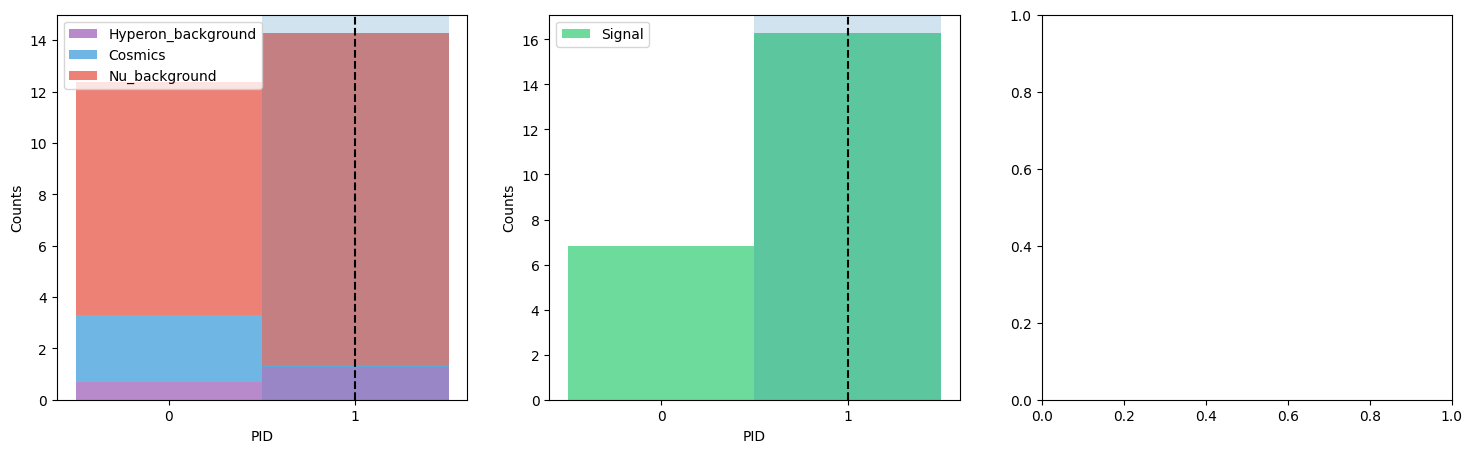

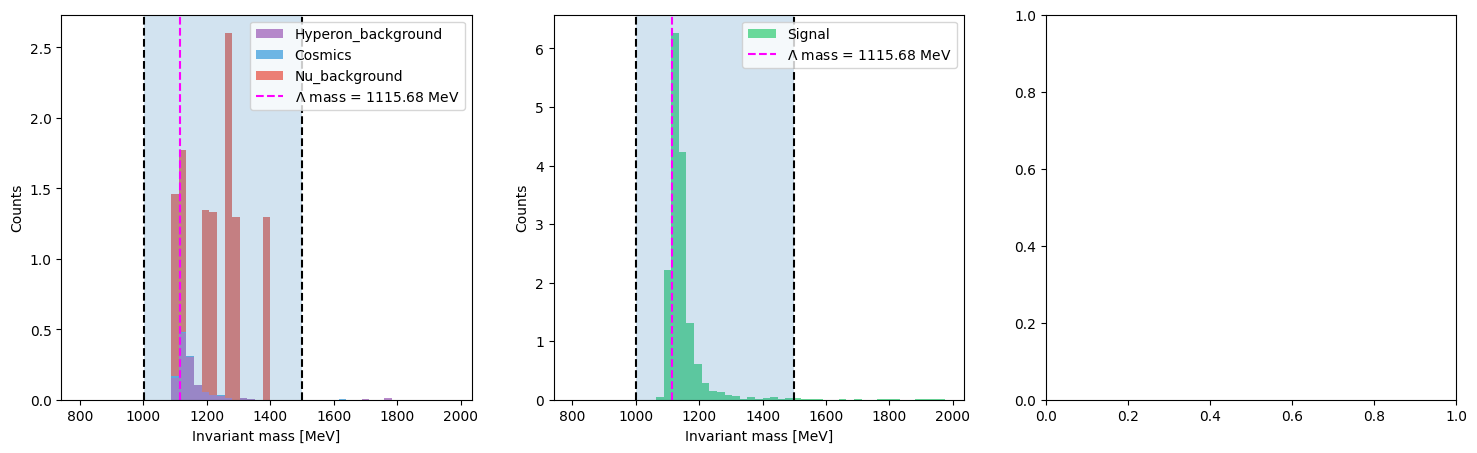

,Stage,Cut value,Signal,Hyperon_background,Cosmics,Nu_background,Cut efficiency (%),Total efficiency (%),Purity (%),Cut bck rejection (%),Total bck rejection (%)
0,PID,== 1,16.3,1.3,0.0,13.0,70.45,3.90,53.28,46.45,99.9999
1,Invariant mass [MeV],"[1000, 1499]",15.6,1.2,0.0,10.4,95.53,3.73,57.33,18.91,100.0000


In [33]:
pid_driver.plot_cuts()
pid_driver.get_cuts_performance(**config['initial_amounts'])

In [34]:
final_pid_df = pid_driver.get_final_df()

In [36]:
len(final_pid_df[final_pid_df.is_lambda_signal])

3186

# Load ana tree

In [30]:
import importlib
import src

importlib.reload(src.branches)
import src.branches as branches


In [31]:
def load_ana_arr(trees, branches, max_entry=None):
    arrays = []
    for t in trees:
        arr = t.arrays(branches, library="ak", entry_stop=max_entry)
        arrays.append(arr)
    return ak.concatenate(arrays, axis=0)



In [32]:
v_analyzer_tdir = "myAnalyzer/tree"

lambda_v_tree = uproot.open(lambda_file)[v_analyzer_tdir]
aurora_v_tree = uproot.open(aurora_file)[v_analyzer_tdir]

In [33]:
v_arr = load_ana_arr([lambda_v_tree,aurora_v_tree], branches.ana)

KeyboardInterrupt: 

In [ ]:
run    = ak.to_numpy(v_arr.run_id)
subrun = ak.to_numpy(v_arr.subrun_id)
event  = ak.to_numpy(v_arr.event_id)

ana_indices = pd.MultiIndex.from_arrays([run, subrun, event])

v_selected_mask = ana_indices.isin(selected_indices)

selected_arr = v_arr[v_selected_mask]

cols = ['is_lambda_signal', 'scale', 'gen_index', 'n_hyperon']

for c in cols:
    selected_arr[c] = final_df.loc[ana_indices[v_selected_mask], c].values

## PID

In [ ]:
def get_v_particles_calo(arr, pfp_vars):
    general_cols = ['file_name', 'event_id', 'run_id', 'is_lambda_signal', 'scale', 'gen_index', 'n_hyperon']
    output = arr[general_cols]

    arr['slc_pfp_vtx_dist2'] = ((arr.slc_vtx_x - arr.slc_pfp_track_start_x)**2
                                + (arr.slc_vtx_y - arr.slc_pfp_track_start_y)**2
                                + (arr.slc_vtx_z - arr.slc_pfp_track_start_z)**2
                               )

    valid_track_mask = ((arr.slc_pfp_chi2_pion > 0)
                        & (arr.slc_pfp_chi2_proton > 0)
                        & (arr.slc_pfp_track_kin_energy > 0)
                        & (arr.slc_pfp_track_start_x > -900)
                        & (arr.slc_pfp_track_start_y > -900)
                        & (arr.slc_pfp_track_start_z > -900)
                        #& (arr.slc_pfp_track_score > 0.5)
                        #& (arr.slc_pfp_is_primary)
                       )


    pfp_cols = ['slc_pfp_track_score', 'slc_pfp_chi2_pion', 'slc_pfp_chi2_proton', 'slc_pfp_track_kin_energy', 'slc_pfp_track_start_x', 'slc_pfp_track_start_y',
                'slc_pfp_track_start_z', 'slc_pfp_is_primary', 'slc_pfp_vtx_dist2'] + pfp_vars

    pfp_arr = arr[pfp_cols]

    pfp_arr['best_pdg'] = ak.where(arr.slc_pfp_chi2_pion < arr.slc_pfp_chi2_proton, 211, 2212)
    valid = pfp_arr[valid_track_mask]
    
    protons = valid[valid.best_pdg == 2212]
    pions   = valid[valid.best_pdg == 211]

    idx_p  = ak.argmin(protons.slc_pfp_vtx_dist2, axis=1, keepdims=True)
    idx_pi = ak.argmin(pions.slc_pfp_vtx_dist2,   axis=1, keepdims=True)

    best_proton = ak.firsts(protons[idx_p])
    best_pion   = ak.firsts(pions[idx_pi])

    output['has_proton'] = ~ak.is_none(best_proton.slc_pfp_track_score)
    output['has_pion']   = ~ak.is_none(best_pion.slc_pfp_track_score)
    output['has_v']       = output['has_proton'] & output['has_pion']

    for v in pfp_vars:
        output = ak.with_field(output, best_proton[v], f"proton_{v}")
        output = ak.with_field(output, best_pion[v],   f"pion_{v}")

    return output
    

In [ ]:
calo_cols = [ 'slc_pfp_track_kin_energy', 'slc_pfp_track_dir_x', 'slc_pfp_track_dir_y', 'slc_pfp_track_dir_z','slc_pfp_true_pdg', 'slc_pfp_chi2_pion', 'slc_pfp_chi2_proton']

ppim_arr = get_v_particles_calo(selected_arr, calo_cols)

In [ ]:
df_cols = ['file_name',
 'event_id',
 'run_id',
 'is_lambda_signal',
 'scale',
 'gen_index',
 'n_hyperon',
 'has_proton',
 'has_pion',
 'has_v',]

ppim_df = ak.to_dataframe(ppim_arr[df_cols])

In [ ]:
with open("../../config/cuts_config.yaml", "r") as f:
    config = yaml.safe_load(f)

my_pid_cuts_config = []

for cut_cfg in config['my_pid_cuts'].values():
    cfg = CutConfig(
        cut = create_cut(cut_cfg['cut']),
        **{k: v for k, v in cut_cfg.items() if k != "cut"}
    )

    my_pid_cuts_config.append(cfg)

In [ ]:
my_pid_driver = AnalysisDriver(ppim_df, my_pid_cuts_config)

In [ ]:
my_pid_driver.plot_cuts()
my_pid_driver.get_cuts_performance(**config['initial_amounts'])

In [ ]:
i = 0

In [ ]:
cols = ['slc_pfp_chi2_pion', 'slc_pfp_chi2_proton', 'slc_pfp_true_pdg', 'is_lambda_signal', 'slc_pfp_track_best_plane']

i+=1

mask = ~ppim_arr.has_v & ppim_arr.is_lambda_signal
selected_arr[cols][mask][i]
